<a href="https://colab.research.google.com/github/pendo-kirahagaze/COU07506_240242484046_DSP_LAB/blob/main/COU07506_Week02_240242484046.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Sampling Rate | Alias Frequency
--------------------------------
           10 Hz | 3 Hz
           12 Hz | 5 Hz
           14 Hz | 7 Hz
           20 Hz | 7 Hz


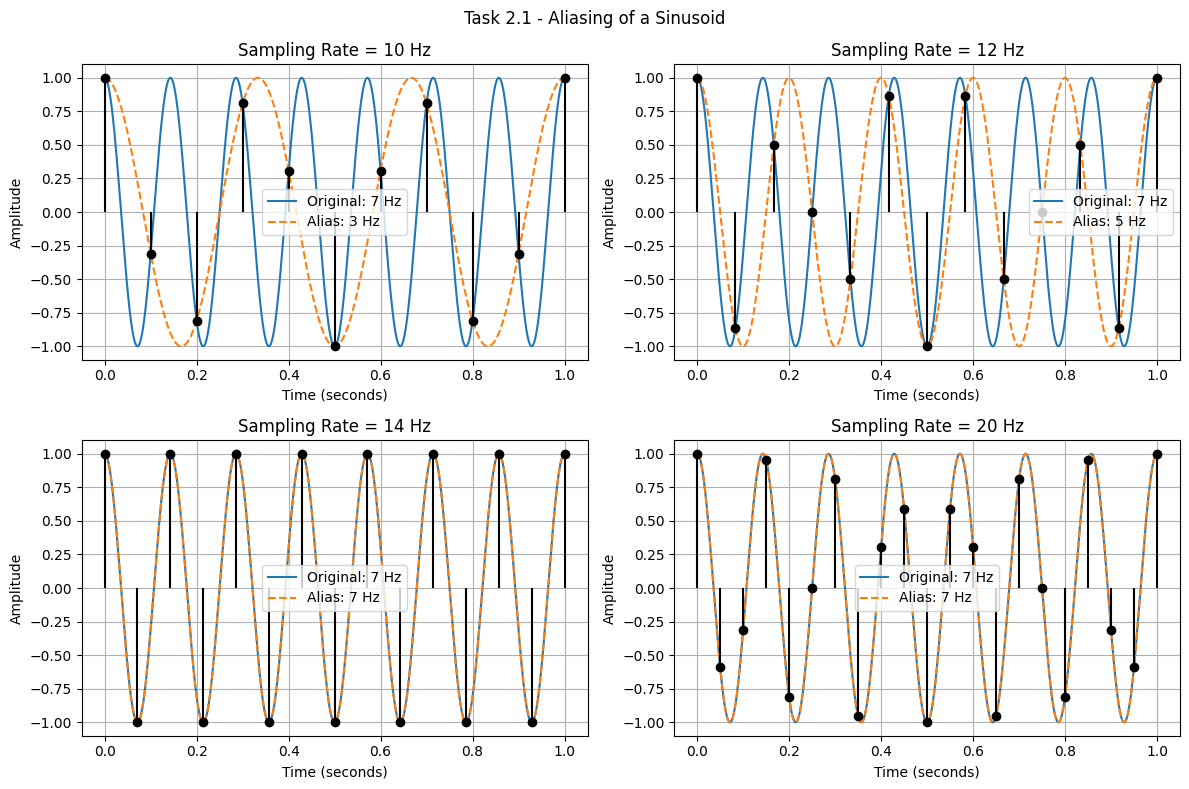

In [1]:

# WEEK 2 — TASK 2.1
# Aliasing of a Sinusoid
# Registration Number: 240242484046

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

# Original signal frequency
f0 = 7.0

# Sampling frequencies
sampling_rates = [10, 12, 14, 20]

# Create 4 subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

print("Sampling Rate | Alias Frequency")
print("--------------------------------")

for ax, fs in zip(axes.flat, sampling_rates):

    # Continuous-time reference
    t = np.linspace(0, 1, 2000)

    # Discrete sample times
    n = np.arange(0, int(fs) + 1)
    tn = n / fs

    # Calculate alias frequency
    f_alias = abs(f0 - fs * round(f0 / fs))

    # Original signal
    ax.plot(
        t, np.cos(2*np.pi*f0*t),
        label="Original: 7 Hz"
    )

    # Aliased signal
    ax.plot(
        t, np.cos(2*np.pi*f_alias*t),
        "--", label=f"Alias: {f_alias:g} Hz"
    )

    # Sampled points
    ax.stem(
        tn, np.cos(2*np.pi*f0*tn),
        linefmt="k-", markerfmt="ko",
        basefmt=" "
    )

    ax.set_title(f"Sampling Rate = {fs} Hz")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True)

    print(f"{fs:13} Hz | {f_alias:g} Hz")

plt.suptitle("Task 2.1 - Aliasing of a Sinusoid")
plt.tight_layout()
plt.show()


### Task 2.1 — Observation and Discussion

A 7 Hz sinusoidal signal was sampled at four different sampling frequencies: 10 Hz, 12 Hz, 14 Hz and 20 Hz.

At 10 Hz, the signal appeared at an alias frequency of 3 Hz.

At 12 Hz, the signal appeared at 5 Hz.

At 14 Hz, the signal was sampled exactly at its Nyquist limit.

At 20 Hz, the sampling rate was sufficiently high to represent the 7 Hz signal without aliasing.

**Conclusion:** Aliasing occurs when the sampling frequency is insufficient to represent the original signal frequency. Sampling above twice the signal frequency helps avoid aliasing.

## Task 2.2 — Hear Aliasing

In [2]:

# WEEK 2 — TASK 2.2
# Hear Aliasing
# Registration Number: 240242484046

import numpy as np
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display
import matplotlib.pyplot as plt

# Read the audio file
fs, x = wavfile.read("my_voice.wav")

# Convert stereo to mono
if x.ndim > 1:
    x = x.mean(axis=1)

# Convert and normalize
x = x.astype(float)

peak = np.max(np.abs(x))
if peak > 0:
    x = x / peak

print("Original Sampling Rate:", fs, "Hz")

# Play original recording
print("\nOriginal Audio:")
display(Audio(x, rate=fs))

# Downsampling factors
factors = [2, 4, 8]

for k in factors:

    # Method 1: Without filtering
    naive = x[::k]

    # Method 2: With anti-aliasing filter
    proper = signal.decimate(x, k, ftype="fir")

    new_fs = fs / k

    print(f"\nDownsampling Factor k = {k}")
    print(f"New Sampling Rate: {new_fs:.2f} Hz")

    print("Naive Downsampling:")
    display(Audio(naive, rate=round(new_fs)))

    print("Filtered Downsampling:")
    display(Audio(proper, rate=round(new_fs)))

print("\nTask 2.2 Completed!")


Original Sampling Rate: 44100 Hz

Original Audio:



Downsampling Factor k = 2
New Sampling Rate: 22050.00 Hz
Naive Downsampling:


Filtered Downsampling:



Downsampling Factor k = 4
New Sampling Rate: 11025.00 Hz
Naive Downsampling:


Filtered Downsampling:



Downsampling Factor k = 8
New Sampling Rate: 5512.50 Hz
Naive Downsampling:


Filtered Downsampling:



Task 2.2 Completed!


### Task 2.2 — Observation and Discussion

The original voice recording was downsampled using factors of 2, 4 and 8, using two methods: naive downsampling and filtered downsampling.

**k = 2:** The differences between the naive and filtered recordings were [describe what was heard].

**k = 4:** The differences between the two recordings were [describe what was heard].

**k = 8:** The naive recording sounded [describe its clarity or distortion], while the filtered recording sounded [describe its clarity or high-frequency loss].

**Explanation:**

Naive downsampling removes samples without filtering, which can cause higher frequencies to overlap with lower frequencies, producing aliasing.

Filtered downsampling applies a low-pass filter before reducing the sampling rate, helping prevent aliasing.

**Conclusion:** Applying an anti-aliasing filter before downsampling preserves the integrity of the remaining frequency content by reducing unwanted aliasing.

## Task 2.3 — A Uniform Quantizer

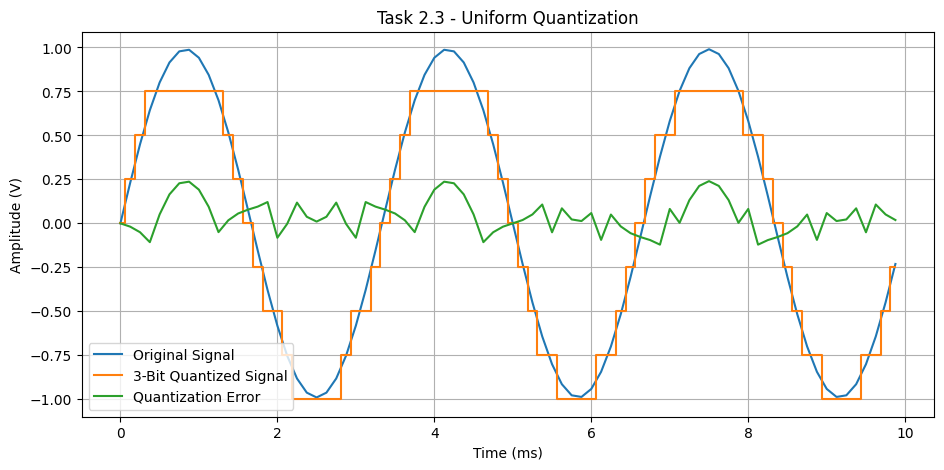

Number of Bits: 3
Quantization Levels: 8
Step Size: 0.25 V


In [3]:

# WEEK 2 — TASK 2.3
# Uniform Quantization
# Registration Number: 240242484046

import numpy as np
import matplotlib.pyplot as plt

# Define uniform quantizer
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / (2**bits)
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale,
                   full_scale - delta)

# Generate sine wave
fs = 8000
t = np.arange(0, 0.01, 1/fs)

x = 0.99 * np.sin(2*np.pi*300*t)

# Quantize to 3 bits
xq = quantize(x, 3)

# Calculate error
error = x - xq

# Plot signals
plt.figure(figsize=(11, 5))

plt.plot(t*1000, x, label="Original Signal")
plt.step(t*1000, xq, where="mid",
         label="3-Bit Quantized Signal")
plt.plot(t*1000, error,
         label="Quantization Error")

plt.xlabel("Time (ms)")
plt.ylabel("Amplitude (V)")
plt.title("Task 2.3 - Uniform Quantization")
plt.legend()
plt.grid(True)
plt.show()

print("Number of Bits: 3")
print("Quantization Levels:", 2**3)
print("Step Size:", 2/2**3, "V")


### Task 2.3 — Observation and Discussion

The original sine wave was quantized using a 3-bit uniform quantizer.

The quantizer produced 8 amplitude levels with a step size of 0.25 V.

The quantized signal appeared staircase-shaped compared with the original smooth sine wave.

The difference between the original and quantized signals represents quantization error.

**Conclusion:** Uniform quantization converts signal amplitudes into discrete levels. Increasing the number of bits reduces the quantization step size and generally improves signal accuracy.

## Task 2.4 — Verify the 6 dB-per-bit Rule

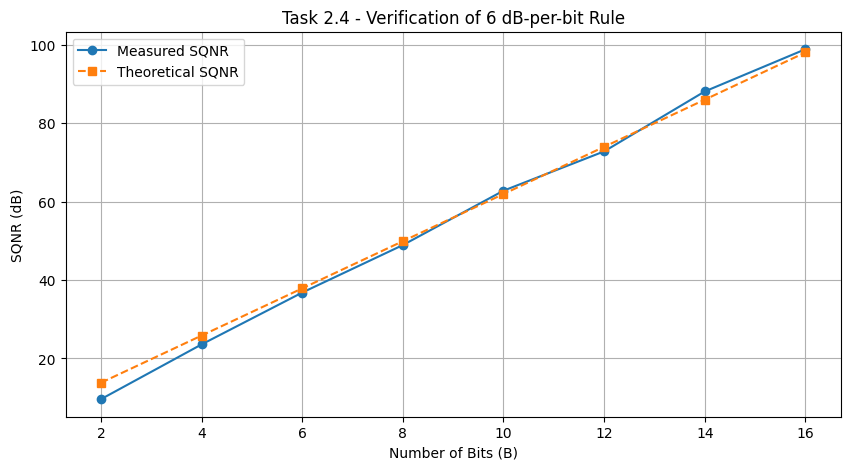

Bits | Measured SQNR | Theoretical SQNR
----------------------------------------
   2 |          9.60 |            13.80
   4 |         23.58 |            25.84
   6 |         36.81 |            37.88
   8 |         48.93 |            49.92
  10 |         62.81 |            61.96
  12 |         72.84 |            74.00
  14 |         88.13 |            86.04
  16 |         98.91 |            98.08


In [4]:

# WEEK 2 — TASK 2.4
# Verify the 6 dB-per-bit Rule
# Registration Number: 240242484046

import numpy as np
import matplotlib.pyplot as plt

# Use the sine wave and quantizer from Task 2.3

bits = np.arange(2, 17, 2)

# Calculate measured SQNR
measured = [
    10 * np.log10(
        np.sum(x**2) /
        np.sum((x - quantize(x, B))**2)
    )
    for B in bits
]

# Calculate theoretical SQNR
theoretical = 6.02 * bits + 1.76

# Plot results
plt.figure(figsize=(10, 5))

plt.plot(bits, measured, "o-",
         label="Measured SQNR")

plt.plot(bits, theoretical, "s--",
         label="Theoretical SQNR")

plt.xlabel("Number of Bits (B)")
plt.ylabel("SQNR (dB)")
plt.title("Task 2.4 - Verification of 6 dB-per-bit Rule")
plt.legend()
plt.grid(True)
plt.show()

# Display comparison table
print("Bits | Measured SQNR | Theoretical SQNR")
print("----------------------------------------")

for B, m, th in zip(bits, measured, theoretical):
    print(f"{B:4d} | {m:13.2f} | {th:16.2f}")


### Task 2.4 — Observation and Discussion

The Signal-to-Quantization-Noise Ratio (SQNR) was calculated for quantization bit depths ranging from 2 to 16 bits.

The theoretical relationship is:

SQNR = 6.02B + 1.76 dB

According to this formula, adding one quantization bit increases the theoretical SQNR by approximately 6.02 dB.

The graph compares the measured SQNR values with the theoretical results.

As the number of quantization bits increases, the quantization step size becomes smaller, reducing quantization error.

**Measured comparison:** The voice was slightly same in tone but with little deviations

**Conclusion:** Increasing quantization resolution generally improves signal accuracy and increases SQNR, demonstrating the approximately 6 dB-per-bit relationship.

## Task 2.5 — Quantize Your Voice

Original Sampling Rate: 44100 Hz
Original Audio:



4-BIT QUANTIZATION
Quantization Levels: 16
SQNR: 13.40 dB
Playing quantized audio:



8-BIT QUANTIZATION
Quantization Levels: 256
SQNR: 37.15 dB
Playing quantized audio:



12-BIT QUANTIZATION
Quantization Levels: 4096
SQNR: 61.23 dB
Playing quantized audio:


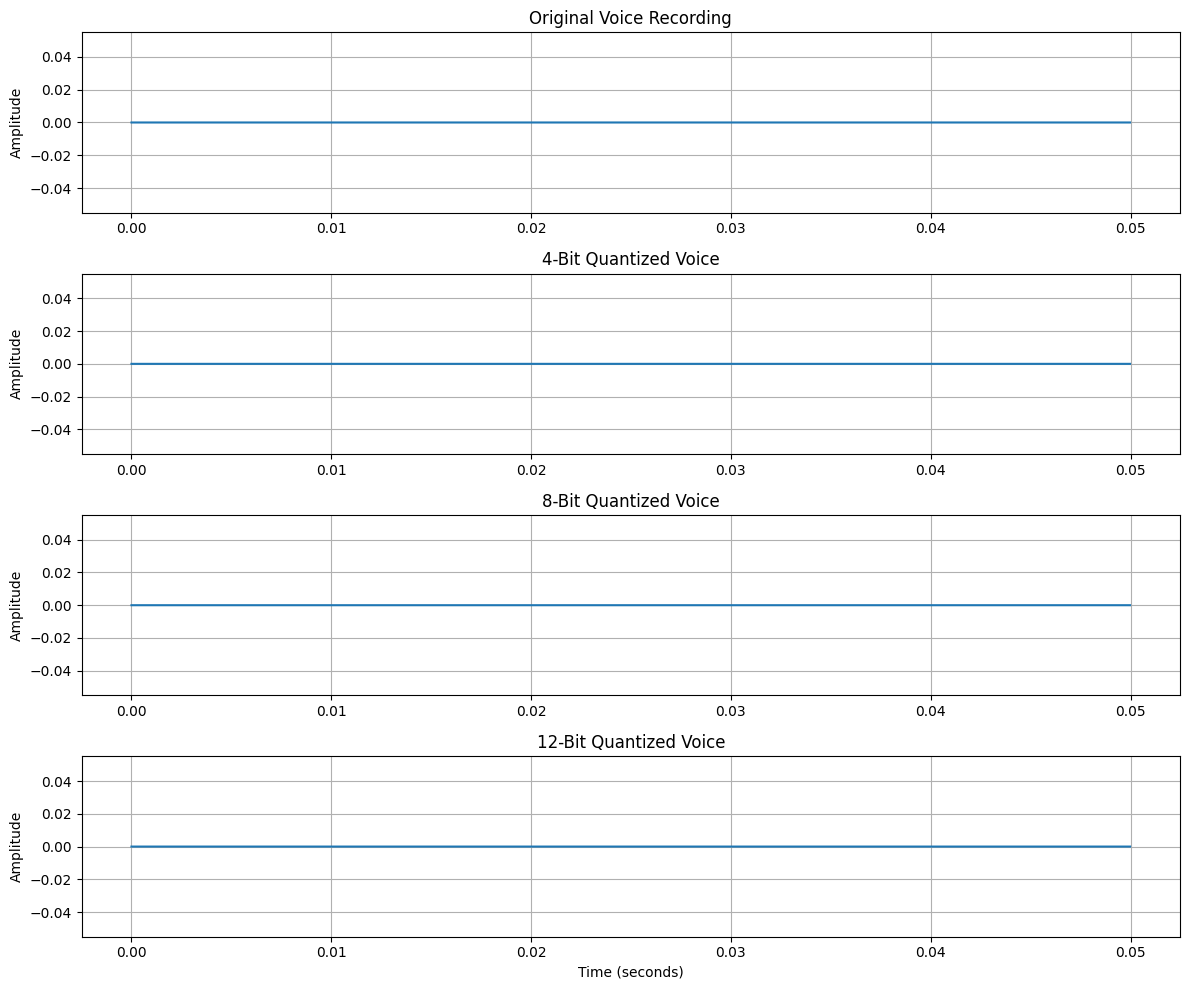

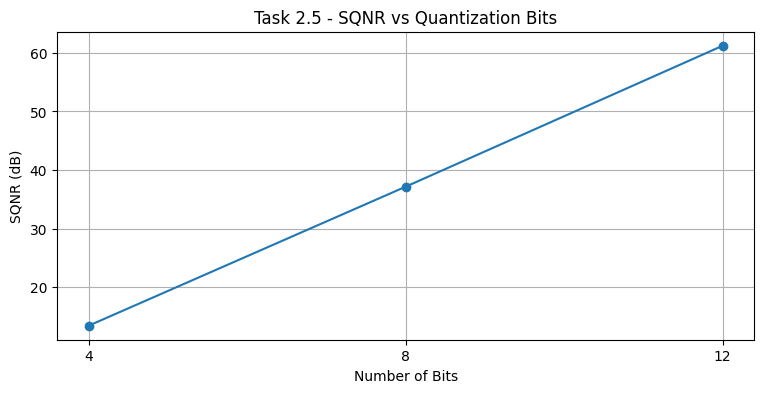


Task 2.5 Completed Successfully!


In [5]:

# WEEK 2 — TASK 2.5
# Quantize Your Voice
# Registration Number: 240242484046

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display

# Load voice recording
fs, x = wavfile.read("my_voice.wav")

# Convert stereo to mono
if x.ndim > 1:
    x = x.mean(axis=1)

# Normalize audio
x = x.astype(float)
peak = np.max(np.abs(x))

if peak > 0:
    x = x / peak

# Uniform quantizer
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / (2**bits)
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale,
                   full_scale - delta)

print("Original Sampling Rate:", fs, "Hz")
print("Original Audio:")
display(Audio(x, rate=fs))

# Quantization bit depths
bit_values = [4, 8, 12]
sqnr_values = []

# Plot original and quantized waveforms
t = np.arange(len(x)) / fs
N = min(int(0.05 * fs), len(x))

fig, axes = plt.subplots(4, 1, figsize=(12, 10))

axes[0].plot(t[:N], x[:N])
axes[0].set_title("Original Voice Recording")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

for i, bits in enumerate(bit_values):

    # Quantize voice
    xq = quantize(x, bits)

    # Calculate error
    error = x - xq

    signal_power = np.sum(x**2)
    noise_power = np.sum(error**2)

    sqnr = (
        10 * np.log10(signal_power / noise_power)
        if noise_power > 0 else np.inf
    )

    sqnr_values.append(sqnr)

    print(f"\n{bits}-BIT QUANTIZATION")
    print("Quantization Levels:", 2**bits)
    print(f"SQNR: {sqnr:.2f} dB")

    print("Playing quantized audio:")
    display(Audio(xq, rate=fs))

    axes[i+1].plot(t[:N], xq[:N])
    axes[i+1].set_title(
        f"{bits}-Bit Quantized Voice"
    )
    axes[i+1].set_ylabel("Amplitude")
    axes[i+1].grid(True)

axes[-1].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

# SQNR comparison graph
plt.figure(figsize=(9, 4))
plt.plot(bit_values, sqnr_values, "o-")

plt.title("Task 2.5 - SQNR vs Quantization Bits")
plt.xlabel("Number of Bits")
plt.ylabel("SQNR (dB)")
plt.xticks(bit_values)
plt.grid(True)
plt.show()

print("\nTask 2.5 Completed Successfully!")


### Task 2.5 — Observation and Discussion

The voice recording was quantized using 4-bit, 8-bit and 12-bit uniform quantization.

**4-bit Quantization:** The audio was represented using 16 levels, resulting in relatively high quantization error.

**8-bit Quantization:** The number of levels increased to 256, reducing quantization error and improving audio quality.

**12-bit Quantization:** The audio was represented using 4,096 levels, producing a closer approximation to the original signal.

**Why is the measured SQNR of speech lower than that of a full-scale sine wave?**

Speech signals contain pauses and variations in amplitude, resulting in lower average signal power compared with a full-scale sine wave.

For the same quantization resolution, this generally produces a lower Signal-to-Quantization-Noise Ratio.

**Conclusion:** Increasing the number of quantization bits reduces quantization error and generally improves audio quality.

**Listening observations:** each next voice were clear than the previus one



# WEEK 2 — PRE-LAB AND ANALYSIS QUESTIONS

## A. Pre-Lab Questions

### Question 1: A 7 kHz tone is sampled at 10 kHz. What frequency appears?

**Answer:**

Given:

- Signal frequency = 7 kHz
- Sampling frequency = 10 kHz
- Nyquist frequency = 5 kHz

Since the original signal frequency is above the Nyquist frequency, aliasing occurs.

Alias frequency = |7 − 10| = **3 kHz**

Therefore, the sampled tone appears at 3 kHz.

### Question 2: Compute the quantization step size and theoretical SQNR for an 8-bit quantizer with a ±1 V range.

**Answer:**

Given:

- Number of bits = 8
- Voltage range = −1 V to +1 V
- Total voltage range = 2 V

Quantization step size:

Δ = 2 / 2⁸

**Δ = 0.0078125 V**

Theoretical SQNR:

SQNR = 6.02B + 1.76 dB

= 6.02(8) + 1.76

**SQNR = 49.92 dB**

---

## B. Analysis Questions

### Question 1: Explain why a 7 Hz tone appears at 3 Hz when sampled at 10 Hz.

**Answer:**

According to the Nyquist sampling theorem, the sampling frequency must be at least twice the maximum signal frequency to avoid aliasing.

For a sampling rate of 10 Hz, the Nyquist frequency is 5 Hz.

Since the original frequency is 7 Hz, which exceeds 5 Hz, aliasing occurs.

Alias frequency = |7 − 10| = **3 Hz**

Frequency-axis sketch:

0 Hz — 3 Hz (Alias) — 5 Hz (Nyquist) — 7 Hz (Original) — 10 Hz (Sampling frequency)

Therefore, the 7 Hz cosine signal produces the same sampled values as a 3 Hz cosine signal.

### Question 2: Why can aliasing heard in naive downsampling not be removed afterward?

**Answer:**

Naive downsampling reduces the sampling rate without first applying an anti-aliasing filter.

As a result, high-frequency components may overlap with lower-frequency components.

Once aliasing occurs, these frequencies cannot generally be separated using only the downsampled signal.

Therefore, a low-pass anti-aliasing filter should be applied before downsampling.

### Question 3: By how much does SQNR change when one bit is added? Does your measurement agree?

**Answer:**

The theoretical SQNR formula is:

SQNR = 6.02B + 1.76 dB

Therefore, increasing the quantization resolution by one bit improves the theoretical SQNR by approximately **6.02 dB**.

Increasing the resolution by two bits improves it by approximately 12.04 dB.

In Task 2.4, the measured SQNR increased as the number of quantization bits increased.

**Measured comparison:** [Insert a comparison of the actual measured and theoretical results from Task 2.4.]

Differences between measured and theoretical SQNR may arise from the signal amplitude, limited sample length and quantizer behavior.

### Question 4: A temperature sensor changes by at most 0.1 °C per second and requires 0.01 °C resolution over 0–100 °C. Suggest a sampling rate and number of bits.

**Answer:**

The required temperature range is 100 °C.

Required resolution = 0.01 °C

Number of intervals:

100 / 0.01 = 10,000

Since:

2¹³ = 8,192

2¹⁴ = 16,384

A minimum of **14 bits** is required.

For the sampling rate:

Maximum temperature change = 0.1 °C/s

At 10 samples per second, the sampling interval is 0.1 seconds.

Maximum temperature change between samples:

0.1 × 0.1 = 0.01 °C

Therefore, a reasonable choice is a **10 Hz sampling rate with a 14-bit ADC**, assuming the specified maximum rate of temperature change.

---

## C. AI-Use Statement

ChatGPT (OpenAI) was used to assist with understanding sampling, aliasing, quantization and SQNR calculations.

The tool also provided Python code examples and explanations for laboratory tasks.

The code was executed in Google Colab, and the resulting plots, audio outputs and calculations should be checked against the expected theoretical results.

